# Figure 4f
Fraction of fixation events with each monitored vertex as the observation. Bars are the predictions of the two structures. Diamonds are the fractions in $20$ fixation events simulated on the true structure, with Clopper-Pearson $95\%$ confidence intervals.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

from fixloc import style as S

d = json.load(open('data.json'))
MONITORED = {2: 4, 3: 3}

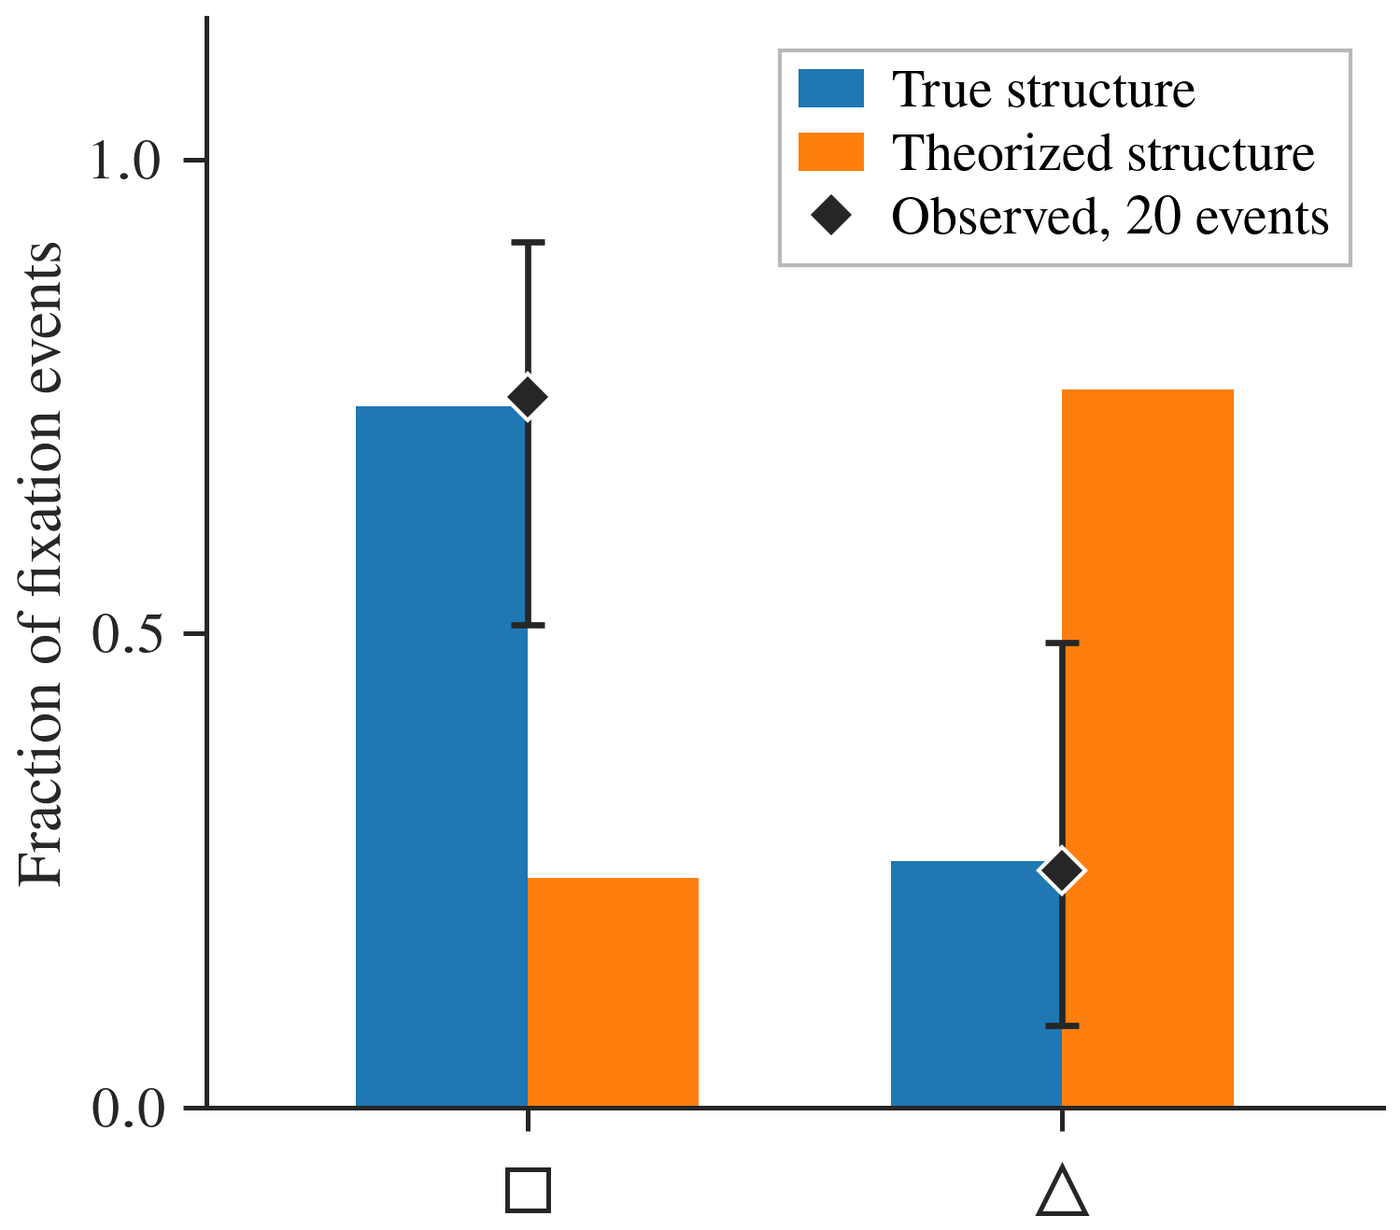

In [2]:
fig = plt.figure(figsize=(7.0, 6.95))
sites = d['monitored']
x = np.arange(2)
w = 0.32
counts = np.array([d['counts'][str(v)] for v in sites])
n = int(counts.sum())
ax = fig.add_axes([0.08, 0.07, 0.30, 0.28])
ax.bar(x - w / 2, d['P_true'], w, color=S.BLUE, label='True structure', zorder=2)
ax.bar(x + w / 2, d['P_theorized'], w, color=S.ORANGE, label='Theorized structure', zorder=2)
lo = np.array([beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0 for k in counts])
hi = np.array([beta.ppf(0.975, k + 1, n - k) if k < n else 1.0 for k in counts])
fr = counts / n
ax.errorbar(x, fr, yerr=[fr - lo, hi - fr], fmt='none', ecolor=S.INK, elinewidth=0.8, capsize=2.2, capthick=0.8, zorder=3.5)
observed = r'Observed, $%d$ events' % n
ax.plot(x, fr, ls='', marker='D', ms=4.2, mfc=S.INK, mec='white', mew=0.5, label=observed, zorder=4)
ax.set_xticks(x)
ax.set_xticklabels(['', ''])
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.5, 1])
tr = ax.get_xaxis_transform()
for k, v in enumerate(sites):
  mk = S.POLY_MARKER[MONITORED[v]]
  ax.plot([k], [-0.075], ls='', marker=mk, ms=6.0 if mk == '^' else 5.2, mfc=S.WILD, mec=S.INK, mew=0.6, transform=tr, clip_on=False, zorder=5)
ax.set_ylabel('Fraction of fixation events')
hs, ls = ax.get_legend_handles_labels()
order = [ls.index('True structure'), ls.index('Theorized structure'), ls.index(observed)]
S.legend(ax, handles=[hs[i] for i in order], labels=[ls[i] for i in order], loc='upper right', handlelength=1.2, borderpad=0.35, labelspacing=0.25)
S.save_panel(fig, 'f')